# Titanic: one leak-free group feature beat tuned trees

**Public LB 0.79425** with a plain logistic regression and one extra feature, built without leaking labels.

| Model (same 5 stratified folds) | CV accuracy | Kaggle public |
|---|---|---|
| Majority class ("everyone died") | 0.616 | - |
| Gender rule ("women survive") | 0.787 | - |
| Logistic regression | 0.831 | 0.76555 |
| Tuned XGBoost (nested CV) | 0.832 | 0.77033 |
| **Logistic regression + group survival** | **0.841** | **0.79425** |

What this notebook shows:
1. A short EDA and simple baselines, so every model has something to beat.
2. All learned preprocessing inside a scikit-learn `Pipeline`, fitted on training folds only.
3. A **group survival** feature (did the other people on your ticket or in your family survive?) and two ways it can leak. One leak is obvious (CV 0.98), the other is subtle (only +0.3 points) and easy to miss.

Full project with tuned trees, nested CV and SHAP: [GitHub](https://github.com/BerkeArdaTurk21/kaggle-titanic) · Write-up: [Medium](https://medium.com/@berkeardaturk/what-my-first-kaggle-project-taught-me-about-data-leakage-and-simple-models-c7c2b174e6f2)

In [1]:
import glob, os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42

# Works on Kaggle (/kaggle/input) and locally (data/raw)
DATA = os.path.dirname((glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("../data/raw/train.csv"))[0])
# The project calls the sex column "Gender"
train = pd.read_csv(os.path.join(DATA, "train.csv")).rename(columns={"Sex": "Gender"})
test = pd.read_csv(os.path.join(DATA, "test.csv")).rename(columns={"Sex": "Gender"})
X, y = train.drop(columns="Survived"), train["Survived"]
print(train.shape, test.shape, f"survival rate {y.mean():.3f}")

(891, 12) (418, 11) survival rate 0.384


## 1. Quick EDA
Gender and class explain most of the story; the passenger's title adds age information.

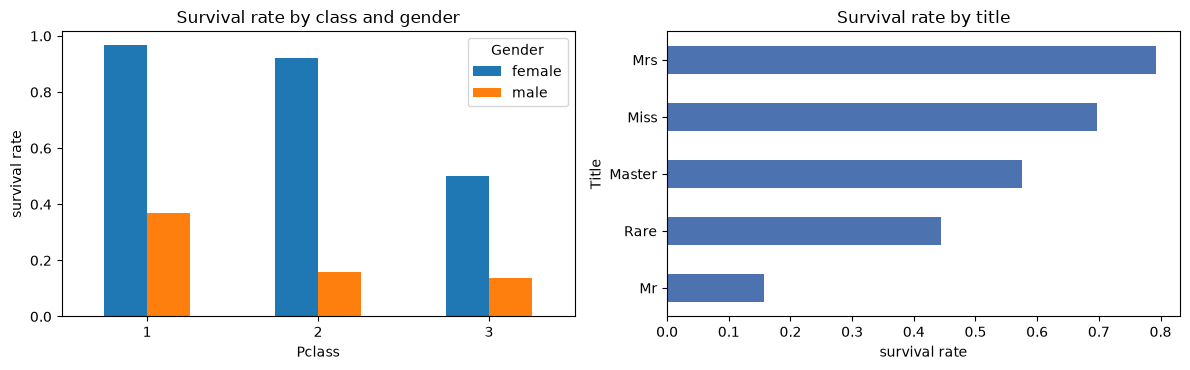

Age         0.199
Cabin       0.771
Embarked    0.002
Name: missing share, dtype: float64


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
pd.crosstab(train["Pclass"], train["Gender"], values=train["Survived"], aggfunc="mean").plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Survival rate by class and gender"); axes[0].set_ylabel("survival rate")
title = train["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare").to_frame("Title").assign(Survived=y) \
    .groupby("Title")["Survived"].mean().sort_values().plot.barh(ax=axes[1], color="#4c72b0")
axes[1].set_title("Survival rate by title"); axes[1].set_xlabel("survival rate")
plt.tight_layout(); plt.show()
print(train.isna().mean().loc[lambda s: s > 0].round(3).rename("missing share"))

## 2. Features
Two kinds of steps:
- `add_features` is stateless (row by row): title, missing-age flag, cabin flag, log fare, family type.
- `TitleAgeImputer` **learns** (median age per title), so it lives inside the Pipeline and is fitted on the training folds only.

In [3]:
COMMON_TITLES = ["Mr", "Mrs", "Miss", "Master"]
TITLE_ALIASES = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
NUMERIC, BINARY = ["Age", "LogFare"], ["AgeMissing", "HasCabin"]
CATEGORICAL = ["Pclass", "Gender", "Title", "FamilyType", "Embarked"]


def extract_title(names):
    titles = names.str.extract(r",\s*([^\.]+)\.", expand=False).str.strip().replace(TITLE_ALIASES)
    return titles.where(titles.isin(COMMON_TITLES), "Rare")


def add_features(df):
    out = df.copy()
    out["Title"] = extract_title(out["Name"])
    out["AgeMissing"] = out["Age"].isna().astype(int)
    out["HasCabin"] = out["Cabin"].notna().astype(int)
    out["LogFare"] = np.log1p(out["Fare"])
    family_size = out["SibSp"] + out["Parch"] + 1
    out["FamilyType"] = pd.cut(family_size, bins=[0, 1, 4, 11], labels=["alone", "small", "large"]).astype(str)
    return out


class TitleAgeImputer(BaseEstimator, TransformerMixin):
    """Fill missing Age with the median age of the passenger's title, learned in fit."""
    def fit(self, X, y=None):
        self.medians_ = X.groupby("Title")["Age"].median()
        self.global_median_ = X["Age"].median()
        return self

    def transform(self, X):
        out = X.copy()
        out["Age"] = out["Age"].fillna(out["Title"].map(self.medians_)).fillna(self.global_median_)
        return out

## 3. The group survival feature
People travelling together (same ticket, or same surname and fare) tended to share a fate. For each passenger the feature is the survival rate of the **other** known members of their group.

It is built from the target, so it leaks unless two rules hold:
1. It is fitted inside the Pipeline, on the training folds only.
2. On training rows the passenger's **own** label is left out (leave-one-out). That is why `fit_transform` differs from `fit().transform()`, like scikit-learn's `TargetEncoder`.

In [4]:
def group_keys(X):
    surname = X["Name"].str.split(",").str[0].str.strip()
    family = surname + "_" + X["Fare"].round(2).astype(str)
    return X["Ticket"].astype(str).to_numpy(), family.to_numpy()


class GroupSurvivalEncoder(BaseEstimator, TransformerMixin):
    """Adds GroupSurvival (rate of other known members, 0.5 if none) and GroupKnown (0/1)."""
    def __init__(self, default=0.5):
        self.default = default

    def fit(self, X, y):
        self.tickets_, self.families_ = group_keys(X)
        self.labels_ = np.asarray(y, dtype=float)
        return self

    def transform(self, X):               # new passengers: all stored labels may be used
        return self._encode(X, leave_one_out=False)

    def fit_transform(self, X, y):        # training rows: drop each passenger's own label
        return self.fit(X, y)._encode(X, leave_one_out=True)

    def _encode(self, X, leave_one_out):
        tickets, families = group_keys(X)
        rates, known = np.full(len(X), self.default), np.zeros(len(X), dtype=int)
        for i, (ticket, family) in enumerate(zip(tickets, families)):
            members = (self.tickets_ == ticket) | (self.families_ == family)
            if leave_one_out:
                members[i] = False
            if members.any():
                rates[i], known[i] = self.labels_[members].mean(), 1
        out = X.copy()
        out["GroupSurvival"], out["GroupKnown"] = rates, known
        return out


def make_preprocessor(group_survival=False):
    numeric = NUMERIC + (["GroupSurvival"] if group_survival else [])
    binary = BINARY + (["GroupKnown"] if group_survival else [])
    columns = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
        ("binary", "passthrough", binary),
        ("categorical", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                      OneHotEncoder(handle_unknown="ignore")), CATEGORICAL),
    ], verbose_feature_names_out=False)
    steps = [("engineer", FunctionTransformer(add_features)), ("impute_age", TitleAgeImputer())]
    if group_survival:
        steps.append(("group_survival", GroupSurvivalEncoder()))
    return Pipeline(steps + [("columns", columns)])


def make_model(estimator, group_survival=False):
    return Pipeline([("prep", make_preprocessor(group_survival)), ("model", estimator)])

## 4. Cross-validation: baselines, the model, and two leaks
Every model is scored on the same `StratifiedKFold(5, shuffle=True, random_state=42)` folds.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}


def evaluate(name, model, data=None):
    scores = cross_validate(model, X if data is None else data, y, cv=cv, scoring="accuracy")
    results[name] = scores["test_score"]
    print(f"{name:<38} CV accuracy {scores['test_score'].mean():.4f} +/- {scores['test_score'].std():.4f}")


class GenderRule(BaseEstimator):
    """Predict survival for women, death for men."""
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        return (X["Gender"] == "female").astype(int).to_numpy()


evaluate("Majority class", DummyClassifier(strategy="most_frequent"))
evaluate("Gender rule", GenderRule())
evaluate("Logistic regression", make_model(LogisticRegression(max_iter=1000)))
evaluate("Logistic regression + group", make_model(LogisticRegression(max_iter=1000), group_survival=True))

# Two wrong ways to build the same feature, for comparison only
leaky = make_model(LogisticRegression(max_iter=1000), group_survival=True).set_params(prep__group_survival="passthrough")
evaluate("LEAK A: own label included", leaky, data=GroupSurvivalEncoder().fit(X, y).transform(X))
evaluate("LEAK B: computed before CV", leaky, data=GroupSurvivalEncoder().fit_transform(X, y))

Majority class                         CV accuracy 0.6162 +/- 0.0023
Gender rule                            CV accuracy 0.7868 +/- 0.0188


Logistic regression                    CV accuracy 0.8305 +/- 0.0099


Logistic regression + group            CV accuracy 0.8406 +/- 0.0162


LEAK A: own label included             CV accuracy 0.9832 +/- 0.0062


LEAK B: computed before CV             CV accuracy 0.8440 +/- 0.0149


**Reading the leaks:**
- **Leak A** (own label inside the feature) is obvious: CV jumps to about 0.98. Nobody would trust that.
- **Leak B** is the dangerous one: leave-one-out is used, but on all rows *before* the split, so validation passengers' labels end up in the training features. It inflates CV by only about 0.3 points, which looks perfectly believable.
- The honest version gains about +1 point over plain logistic regression and never loses on a fold:

In [6]:
folds = pd.DataFrame(results).drop(columns=[c for c in results if c.startswith("LEAK")])
folds.index = [f"fold {i + 1}" for i in range(len(folds))]
folds["group gain"] = folds["Logistic regression + group"] - folds["Logistic regression"]
folds.round(3)

,Majority class,Gender rule,Logistic regression,Logistic regression + group,group gain
fold 1,0.615,0.788,0.844,0.844,0.000
fold 2,0.618,0.775,0.826,0.831,0.006
fold 3,0.618,0.787,0.815,0.815,0.000
fold 4,0.618,0.764,0.837,0.860,0.022
fold 5,0.612,0.820,0.831,0.854,0.022


## 5. Submission
Fit on all training rows (the encoder sees every label, leaving each training passenger's own label out) and predict the test set.

In [7]:
final = make_model(LogisticRegression(max_iter=1000), group_survival=True).fit(X, y)
submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": final.predict(test)})
submission.to_csv("submission.csv", index=False)
known = final.named_steps["prep"].named_steps["group_survival"].transform(
    final.named_steps["prep"].named_steps["impute_age"].transform(add_features(test)))["GroupKnown"].mean()
print(f"predicted survival rate {submission.Survived.mean():.3f} | test passengers with a known group member: {known:.1%}")
submission.head()

predicted survival rate 0.373 | test passengers with a known group member: 40.9%


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


## Takeaways
- **Baselines first.** The gender rule alone scores 0.787; a model that does not clearly beat it has learned nothing useful.
- **Tuned trees did not help here.** Random forest and XGBoost tied with logistic regression (about 0.83) once tuned with nested CV, so the simpler model wins.
- **New information beats more tuning.** The group feature added about +1 point in CV and +2.9 points on the public LB (0.76555 to 0.79425).
- **Target-based features need two guards:** fit them inside the Pipeline, and leave each row's own label out.
- **CV vs LB:** CV is about 0.84 but LB about 0.79; the 418-passenger test set is small, so treat single LB numbers as noisy and choose models by CV.

SHAP analysis, tuned trees and the full write-up: [GitHub](https://github.com/BerkeArdaTurk21/kaggle-titanic) · [Medium](https://medium.com/@berkeardaturk/what-my-first-kaggle-project-taught-me-about-data-leakage-and-simple-models-c7c2b174e6f2)

If this helped, an upvote is appreciated.